# Create guidance conditions

How to make the guidance condition files for DynaGuide (`pos_examples` and `neg_examples` of an experiment config) from recorded data.

The authors only published the conditions for `switch_on`. They made theirs by cutting the recorded CALVIN play data into behaviors and taking the last frame of each piece. This pipeline does the same with any recording you have, and it can also search for frames in a state that you describe.

| Part | What it does |
| --- | --- |
| [dynaguide_scripts/create_guidance_conditions.py](dynaguide_scripts/create_guidance_conditions.py) | The command you run, from the `DynaGuide-main` folder |
| [core/guidance_conditions.py](core/guidance_conditions.py) | The pipeline, also usable from Python as in this notebook |
| [calvin_exp_configs_examples/guidance_goals](calvin_exp_configs_examples/guidance_goals) | Example of a goals file |

Any source becomes a list of `Recording` (states, proprio, actions and images per frame), so everything after reading is the same for all sources:

```
CALVIN folder (.npz)  ─┐                      ┌─ segment_recording  one file per behavior ─┐
                       ├─ read_recordings  ─> │                                            ├─ write_conditions  .hdf5 + preview .png + manifest
rollout .hdf5         ─┘                      └─ find_frames        one file per goal     ─┘
```

## What a guidance condition contains

A condition file is a robomimic-style hdf5 with one demo per condition. **`calculate_classifier_guidance` only uses the last frame of each demo**, and from it:

| Used for guidance | Stored but not used |
| --- | --- |
| `obs/third_person`: the image from the external camera | `obs/eye_in_hand` |
| `obs/proprio`: the robot state | `obs/states`: the scene, only for searching and checking |
| `actions`: the last action, repeated to the 16 steps of a chunk | The earlier frames, which are there to look at |

DINO only sees the image, and the dynamics model adds proprio and actions to it. So a condition is more than a picture, as long as `state_action_embedding` is used in [core/dynaguide.py](core/dynaguide.py).

## Prerequisites

The packages of the DynaGuide env are enough, the pipeline needs `h5py`, `opencv-python` and `scipy` and no GPU. Run everything from the `DynaGuide-main` folder.

The examples use the CALVIN debug set (1.3 GB, scene D) in `datasets/calvin_debug_dataset`. Pass its `validation` or `training` folder, not the folder above them. `datasets/` is ignored by git, so the results stay on your machine.

In [1]:
import glob, json, os, tempfile
import matplotlib.pyplot as plt

from core.guidance_conditions import (build_behavior_conditions, build_goal_conditions, find_frames, read_recordings,
                                      segment_recording, select_frames)

VALIDATION = "datasets/calvin_debug_dataset/validation"
TRAINING = "datasets/calvin_debug_dataset/training"
EXAMPLE_FOLDER = tempfile.mkdtemp() # this notebook writes to a temporary folder, so running it changes nothing else

def show(path, title = None, width = 11):
    image = plt.imread(path)
    plt.figure(figsize = (width, width * image.shape[0] / image.shape[1]))
    plt.imshow(image); plt.axis("off")
    if title: plt.title(title)
    plt.show()

recordings = read_recordings([VALIDATION, TRAINING])
for recording in recordings:
    print(recording.name, len(recording), "frames, cameras", recording.cameras)

validation_ep0 1675 frames, cameras ['third_person', 'eye_in_hand']
training_ep0 2771 frames, cameras ['third_person', 'eye_in_hand']


## 1. One condition file per behavior

This cuts the recordings the way the authors did. The output is the same as the authors' `calvin_to_labeled_hdf5.py`: on the debug set all 79 demos came out byte-identical.

Run this in a terminal. On Windows put it on one line, or end the lines with `^` instead of `\`:

```bash
python dynaguide_scripts/create_guidance_conditions.py \
    --recordings datasets/calvin_debug_dataset/validation datasets/calvin_debug_dataset/training \
    --output_folder datasets/guidance_conditions/debug_all
```

Options:

| Option | Meaning |
| --- | --- |
| `--recordings` | Any number of CALVIN folders and hdf5 files, also mixed |
| `--output_folder` | Must be new or empty, the tool stops instead of overwriting |
| `--behaviors drawer_open door_left` | Only these. By default all but `other` |
| `--max_per_behavior 20` | A limit per behavior, like the 20 of the paper |

The same from Python:

In [2]:
behavior_folder = os.path.join(EXAMPLE_FOLDER, "behaviors")
counts = build_behavior_conditions(recordings, behavior_folder)
print(json.dumps(counts, indent = 2))
print(sorted(os.listdir(behavior_folder))[:4], "...")

{
  "blue_displace": 7,
  "blue_lift": 7,
  "button_off": 3,
  "button_on": 3,
  "door_left": 4,
  "door_right": 3,
  "drawer_close": 3,
  "drawer_open": 4,
  "pink_displace": 7,
  "pink_lift": 7,
  "red_displace": 7,
  "red_lift": 9,
  "switch_off": 3,
  "switch_on": 4
}
['blue_displace.hdf5', 'blue_displace.png', 'blue_lift.hdf5', 'blue_lift.png'] ...


Always look at the preview before you use a file. It shows the last frame of each condition, which is what the guidance uses. The label on each image is its source: recording and frame number.

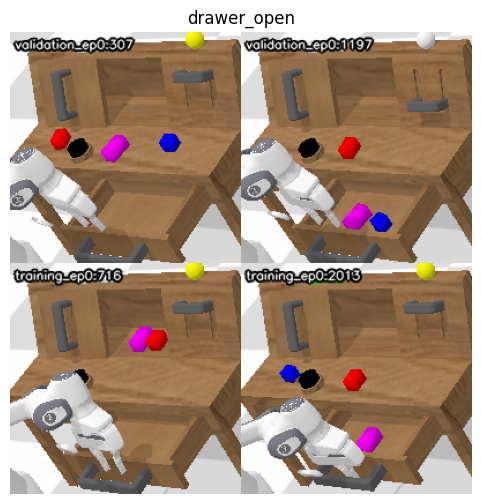

In [3]:
show(os.path.join(behavior_folder, "drawer_open.png"), "drawer_open", width = 6)

What the labels mean, from the authors' logic:

- **`drawer_open`, `door_left`, `switch_on`, ...:** the joint went from one end to the other, with the thresholds in `ARTICULATED` of [core/calvin_behaviors.py](core/calvin_behaviors.py).
- **`red_lift`, ...:** ends at the moment a block near the robot **starts** to move. The block isn't up yet, so for a grasped block use a goal (section 2).
- **`red_displace`, ...:** the block moved during the segment. This check is copied as it is from the authors, and it only finds blocks that moved towards larger x, y or z.

`manifest_behaviors.json` in the output folder lists where each condition came from and its state.

## 2. One condition file per goal

Behaviors only cover the end of a recognized motion. For intermediate goals you describe the state, and the tool finds matching frames. A goals file holds any number of these:

```json
{
    "goals" : [
        {"name" : "drawer_open_hand_near", "n" : 5,
         "where" : {"drawer" : "open", "tcp_near" : "drawer_handle"}},

        {"name" : "block_lifted", "n" : 5,
         "where" : {"blocks" : {"blue" : "lifted"}}}
    ]
}
```

```bash
python dynaguide_scripts/create_guidance_conditions.py \
    --recordings datasets/calvin_debug_dataset/validation datasets/calvin_debug_dataset/training \
    --goals calvin_exp_configs_examples/guidance_goals/drawer_door_block.json \
    --output_folder datasets/guidance_conditions/my_goals
```

What `where` can contain, all of it has to match:

| Key | Values |
| --- | --- |
| `drawer` | `open` / `closed`, or a range `[0.1, 0.2]` |
| `sliding_door` | `left` / `right`, or a range |
| `switch`, `green_light` | `on` / `off`, or a range |
| `button` | `pressed` (from 0.015, fully pressed is about 0.027) / `released`, or a range. The button springs back by itself, so pressing frames only exist during a press |
| `blocks` | `{"red" : "drawer"}` with `drawer`, `table`, `cabinet`, `cabinet_left`, `cabinet_right`, `held`, `lifted` |
| `tcp_near` | `drawer_handle`, `door_handle`, `switch`, `button`, a block `red` / `blue` / `pink`, or `[x, y, z]` |
| `tcp_radius` | How close for `tcp_near`, 0.08 m by default |
| `gripper` | `open` / `closed` |

`held` means the gripper is closed around the block, and `lifted` means it's also off its resting height.

Options of a goal:

| Key | Meaning |
| --- | --- |
| `n` | How many conditions. Without it, one per separate match |
| `min_gap` | Frames between two picks of the same match, 15 by default, because neighbouring frames look the same |
| `exclude` | Labels to leave out, like `["validation_ep0:1234"]`. See below |
| `history` | Frames saved before the chosen one, 16 by default. Only for looking at, the guidance uses the last |

A typo stops the tool before it writes anything. A goal without a match prints `0` and writes no file.

{
  "drawer_open_hand_near": 5,
  "door_left_hand_near": 5,
  "block_lifted": 5,
  "block_lifted_over_open_drawer": 5,
  "block_in_open_drawer_hand_near": 3
}


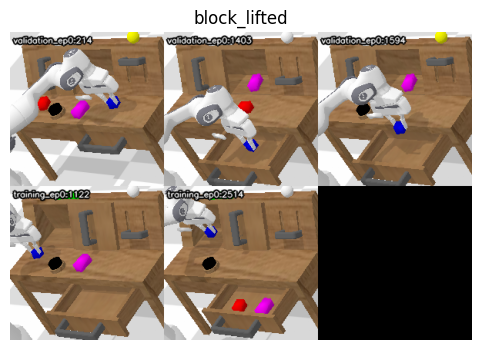

In [4]:
with open("calvin_exp_configs_examples/guidance_goals/drawer_door_block.json") as f:
    goals = json.load(f)["goals"]

goal_folder = os.path.join(EXAMPLE_FOLDER, "goals")
print(json.dumps(build_goal_conditions(recordings, goals, goal_folder), indent = 2))
show(os.path.join(goal_folder, "block_lifted.png"), "block_lifted", width = 6)

**Trying out a description.** This counts the matches without writing anything, which is the quickest way to tune a goal. One separate match is one visit to that state, so few matches mean few really different conditions.

In [5]:
where = {"drawer" : "open", "sliding_door" : "left", "blocks" : {"blue" : "drawer"}}

for recording in recordings:
    print(recording.name, "matching frames:", int(find_frames(recording, where).sum()))

masks = [find_frames(recording, where) for recording in recordings]
print("picks:", [f"{recording.name}:{frame}" for recording, frame in select_frames(recordings, masks)])

validation_ep0 matching frames: 460
training_ep0 matching frames: 0
picks: ['validation_ep0:641', 'validation_ep0:1400', 'validation_ep0:1674']


**Removing a bad condition.** Copy its label from the preview into `exclude` and run again into a new folder. With `n` set, another frame takes its place:

```json
{"name" : "block_lifted", "n" : 5, "exclude" : ["validation_ep0:1234"], "where" : {"blocks" : {"blue" : "lifted"}}}
```

## 3. Using the files in an experiment

A condition file goes into `pos_examples`, or `neg_examples` with `use_neg` set to `true`. Remember to keep the goal and the start state consistent, `run_dynaguide.py` checks this before it starts:

```json
{
    "target_behaviors" : ["drawer_open"],
    "env_setup" : {"drawer" : "closed"},
    "use_neg" : false,
    "pos_examples": "datasets/guidance_conditions/debug_all/drawer_open.hdf5",
    "reset_poses": "calvin_exp_configs_examples/reset_poses/initial_calvin_robot_states_right_side_midpoint.json"
}
```

## 4. Conditions from your own rollouts

Rollouts go through the same pipeline. They only need their images, which `run_dynaguide.py` normally throws away to save space, so add `--dataset_images`. A rollout then takes around 20 KB per frame. Everything else stays the same:

```bash
python dynaguide_scripts/run_dynaguide.py --dataset_images <your usual arguments> --output_folder results/my_rollouts
```

The rollouts land in `<output_folder>/<date>_rollout.hdf5`. Pass that file to `--recordings`, also together with other sources:

```bash
python dynaguide_scripts/create_guidance_conditions.py \
    --recordings results/my_rollouts/2026-11-08_10-00-00_rollout.hdf5 datasets/calvin_debug_dataset/validation \
    --output_folder datasets/guidance_conditions/from_rollouts
```

Each rollout of the file is one recording, named like `2026-11-08_10-00-00_rollout_demo_3`. A rollout stops the moment its goal is reached, so unlike the authors the pipeline also keeps the unfinished motion at the end of a recording if it has a name. Otherwise it would lose exactly the goal.

Keep in mind that a rollout file with images holds every rollout you ran, the failed ones too, and the labels come from the states and not from the success of the run. Check the preview.

Existing condition files also work as `--recordings`, with goals for example, to search inside them.

## 5. More conditions from guided rollouts: harvest

The base policy alone rarely does a task, so conditions from its rollouts come slowly. [harvest_rollouts.py](dynaguide_scripts/harvest_rollouts.py) runs **guided** rollouts instead, for every goal of a plan and from every start state, and cuts the results into new condition files. It is made to run unattended on the workstation.

**The plan** [calvin_exp_configs_examples/harvest/articulated.json](calvin_exp_configs_examples/harvest/articulated.json) covers drawer, sliding door and switch. A goal's own joint starts where the goal can happen, the other two take all 4 combinations. So the conditions of each goal show the rest of the scene in every state:

| Goal | Fixed at the start | Varies, 4 start states |
| --- | --- | --- |
| `drawer_open` / `drawer_close` | drawer closed / open | door right, left × switch off, on |
| `door_left` / `door_right` | door right / left | drawer closed, open × switch off, on |
| `switch_on` / `switch_off` | switch off / on | drawer closed, open × door right, left |

That's 24 tasks, 240 rollouts with `"n_rollouts" : 10`. Blocks, the green light and the robot start pose (out of `reset_poses`) stay random. The plan's fields:

| Field | Meaning |
| --- | --- |
| `joints` | The joints and their words, all combinations are used. Any of `drawer`, `sliding_door`, `switch`, `green_light` |
| `goals` | Goal name: its conditions (a path, a list, or patterns with `*`, like `pos_examples`), or `{"conditions" : ..., "scale" : 1, "alpha" : 40}` to change the guidance settings for this goal. The example uses the paper's settings per task |
| `n_rollouts`, `horizon` | Per task |
| `scale`, `ss`, `alpha` | Guidance settings for every goal that doesn't set its own |
| `reset_poses` | Robot start poses, as in an experiment config |

**Running it.** First list the tasks, then try one goal in its own folder to see the success rate and the time per task, then start the whole plan:

```bat
python dynaguide_scripts\harvest_rollouts.py --plan calvin_exp_configs_examples\harvest\articulated.json --output_folder results\harvest_articulated --dry_run

python dynaguide_scripts\harvest_rollouts.py --plan calvin_exp_configs_examples\harvest\articulated.json --output_folder results\harvest_trial ^
    --agent base_policy_300.pth --guidance dynamics_model_5900.pth --goals drawer_open

python dynaguide_scripts\harvest_rollouts.py --plan calvin_exp_configs_examples\harvest\articulated.json --output_folder results\harvest_articulated ^
    --agent base_policy_300.pth --guidance dynamics_model_5900.pth
```

There is no PyBullet window, the console is the only sign of life. Every 2 minutes (`--status_minutes`) a running task prints how far it is, and after each task the result and the hours left:

```
[14:02] task 1 / 24: drawer_open/drawer_closed__door_right__switch_off
  [14:04] running for 2 min: loading the models and the conditions
  [14:06] running for 4 min: rollout 1 / 10 at step ~126 / 400, goal reached 0 / 0 so far
  ...
  4 / 10 reached drawer_open in 31.5 min, behaviors {'drawer_open': 4, 'no_behavior': 5, 'switch_on': 1}
[14:34] task 2 / 24: drawer_open/drawer_closed__door_right__switch_on, about 12.1 h left
```

`WARNING: no new output for 10 min` means the task is probably stuck: look at its `console.txt`, stop with Ctrl+C and start again.

**When something goes wrong.** Each task is its own `run_dynaguide.py` process, so a crash only loses that task and the next one starts. After 3 failed tasks in a row the harvest stops, because that usually means a broken setup such as a wrong path. To continue after a stop, a crash or Ctrl+C, start the same command again: finished tasks are skipped, the unfinished one is moved to `_incomplete/` and runs again with the same seed. A different plan can't continue in the same folder.

**The output folder:**

```
results/harvest_articulated/
  plan.json                     the plan of this harvest
  summary.json                  every task with its status and successes, updated after each task
  drawer_open/                  one folder per goal
    drawer_closed__door_right__switch_off/      one per start state, a normal run_dynaguide.py output folder plus
      config.json               its experiment config, also works with preview_resets.py
      console.txt               everything run_dynaguide.py printed
      DONE                      written once the task finished, with its numbers
  _incomplete/                  crashed or interrupted attempts
  conditions_<date>_<time>/     one condition file per behavior from all finished rollouts
```

At the end, the harvest cuts **all** finished rollouts into one condition file per behavior, like section 1. The labels come from the states, so a switch the robot hit on its way to the drawer also becomes a `switch_on` condition. A preview label like `drawer_open/drawer_closed/door_right/switch_off/demo_3:212` names the task, the start state, the rollout and the frame. To rebuild the conditions without running anything, for example while the harvest is still going:

```bat
python dynaguide_scripts\harvest_rollouts.py --plan calvin_exp_configs_examples\harvest\articulated.json --output_folder results\harvest_articulated --conditions_only
```

**A second round.** The example plan starts from the few conditions of the debug set (3 to 4 per goal, 20 for `switch_on`). Once a harvest gives more, copy the plan, point its goals at the new `conditions_*` files and run it into a new folder.

## Combining condition files

**In the config, no new file needed.** `pos_examples` and `neg_examples` take a list of files, and patterns with `*`. `run_dynaguide.py` then uses all of them together, see "Experiment configs" in `DynaGuide_Experiments.ipynb`:

```json
"pos_examples" : ["datasets/guidance_conditions/recombined_debug/drawer_open/*.hdf5",
                  "datasets/guidance_conditions/recombined_debug_no_blocks/drawer_open/*.hdf5"]
```

The same works for the goals of a harvest plan and the condition sets of `run_experiments.py`.

**As one file.** If you need a single file, for example for `run_sampling_baseline.py`, the authors have [data_processing_calvin/hdf5_combiner.py](data_processing_calvin/hdf5_combiner.py). It copies the demos of the listed files one after another into a new file. It has no command line: write the input files into `sets_to_combine` and the result into `output_file` at the top of the script. `accept_cap` takes at most that many demos per file, picked at random. It makes no preview, so check the result with `helper_scripts/show_guidance_images.py`.

## 6. Same robots, every scene: recombine

A condition only needs a realistic robot at the goal, and the robot is the hard part to get. The scene around it is easy to set. [dynaguide_scripts/recombine_conditions.py](dynaguide_scripts/recombine_conditions.py) takes the last frame of each existing condition and puts the robot back into the simulator exactly as it was: arm joints, gripper and action from the recorded proprio and action. Then it renders the frame again with every combination of drawer, door, switch and green light. No policy or GPU is needed, a run over the debug set takes about 30 seconds.

```bash
python dynaguide_scripts/recombine_conditions.py --output_folder datasets/guidance_conditions/recombined_debug
python dynaguide_scripts/recombine_conditions.py --output_folder datasets/guidance_conditions/recombined_debug_no_blocks --hide_blocks
```

**All at once on Windows.** [dynaguide_scripts/make_guidance_conditions.bat](dynaguide_scripts/make_guidance_conditions.bat) makes every condition of this notebook from the debug set in one go: the behaviors of section 1 (`debug_all`), the button presses below (`button_pressed`), and both recombined folders. It expects the debug set in `DynaGuide-main\datasets\calvin_debug_dataset` and writes into `DynaGuide-main\datasets\guidance_conditions`. It works from any folder, and stops instead of overwriting a folder that is already there:

```bat
conda activate dynaguide
DynaGuide-main\dynaguide_scripts\make_guidance_conditions.bat
```

By default it takes the six files `drawer_open`, `drawer_close`, `door_left`, `door_right`, `switch_on`, `switch_off` of `datasets/guidance_conditions/debug_all` (3 to 4 conditions each), and `button_on` and `button_off` of `datasets/guidance_conditions/button_pressed`. Other sources, like the conditions of a harvest or `guidance_condition_switch_on_20.hdf5`, go in with `--conditions`. Any file whose behavior is one of those eight works.

**The button.** The authors' cut of the recordings only gives `button_on` when the green light goes from off to on, and ends after the button sprang back, so the robot hovers above it. The debug set has 6 presses: 3 switch the light on, 3 switch it off. The robot and the button look the same in both, so all 6 are used, from a frame search for the button pressed down with the gripper on it:

```bash
python dynaguide_scripts/create_guidance_conditions.py --recordings datasets/calvin_debug_dataset/validation datasets/calvin_debug_dataset/training --goals calvin_exp_configs_examples/guidance_goals/button_pressed.json --output_folder datasets/guidance_conditions/button_pressed
```

This writes the same 6 frames twice, as `button_on.hdf5` and `button_off.hdf5`. For these two behaviors `dynaguide_scripts/recombine_conditions.py` sets the green light to the goal's state, on for `button_on` and off for `button_off`. Nothing touches the lamp itself, so that doesn't change the robot or the button. Run this before `dynaguide_scripts/recombine_conditions.py`, which takes these two files by default.

| Option | Meaning |
| --- | --- |
| `--output_folder` | Must be new or empty |
| `--conditions` | Condition files to take the robots from |
| `--joints` | Joints to combine, by default `drawer sliding_door switch green_light`. Fewer joints give fewer files |
| `--near_radius` | A joint whose handle is this close to the gripper doesn't move, 0.1 m by default. For the green light that's the button |
| `--hide_blocks` | No blocks in any image, they are parked outside the camera view |

**What changes and what stays.** For each condition:

- The robot, its action and the joint of the goal stay, like the drawer in a `drawer_open` condition. For the button goals, the button stays pressed and the green light is set to the goal's state.
- A joint the gripper holds or is close to (`--near_radius`) stays as well. A combination that would need to move it skips this condition.
- Every other joint takes both of its states. The yellow light follows the switch. The green light belongs to the button, which toggles it with each press and isn't moved here, so the green light is set directly, as the button would leave it.
- Blocks stay where they were, and blocks in the drawer move with it. A block that would end up inside the table, the door, the drawer or the robot blocks the movement and is removed from the scene. On the debug set this happened 32 times, always a block in the path of the sliding door in a `door_right` combination. With `--hide_blocks` there are no blocks at all.
- A combination where the robot would end up inside the table skips this condition. On the debug set this never happened: when a joint the robot doesn't hold moves, it moves away from the gripper.

**The output.** One folder per behavior with one file per combination, 8 per behavior and 64 in all, named after the whole scene, the goal's joint in its end state. Each file holds all conditions of that behavior. `recombined_debug_no_blocks` has the same layout:

```
datasets/guidance_conditions/recombined_debug/
  manifest.json                                                  per file: the conditions, the removed blocks, what was skipped and why
  drawer_close/
    drawer_closed__door_left__switch_off__green_light_off.hdf5   the 3 drawer_close robots in this scene
    drawer_closed__door_left__switch_off__green_light_off.png    preview, like every condition file
    drawer_closed__door_left__switch_off__green_light_on.hdf5
    ...                                                          8 combinations per behavior
    overview.png                                                 every robot (row) in every combination (column), black where skipped
  drawer_open/ ...
```

**How it was checked.** Rendering each condition again in its own scene gives the same robot as the original, within 1 mm at the gripper. The image differs from the original by about 20 / 255 on average: that's the renderer (CPU instead of the EGL of the CALVIN data), not the scene. The files load through `MultiviewDataset`, and their proprio and action chunk are identical to the original conditions. In both folders the green light of all conditions matches the file name, and the folder without blocks has none in view. The 6 button presses were checked by eye: the gripper is on the pressed button in each.

**What to keep in mind:**

- **Renderer.** All images of a run come from the simulator, the original scene too. So they match what the policy sees in the simulator on Windows, but not exactly the training images.
- **Without blocks.** CALVIN always has its three blocks, so the policy and the dynamics model never saw an empty table in training. Conditions without blocks are cleaner, but further from what the models know. For experiments, a scene without blocks needs `"blocks" : {"red" : "hidden", "blue" : "hidden", "pink" : "hidden"}` in `env_setup`.
- **Same robot, same action.** The files of a behavior share the robot poses, only the scene changes. The variety of the robot only grows with more source conditions, for example from a harvest.
- **Single frame.** Each condition is only its last frame, without the history before it. The guidance only uses that frame. A preview label like `validation_ep0:661:0` is the source frame `validation_ep0:661`.
- **Combining files.** To use several combinations together, or with other conditions, list them or use a pattern in `pos_examples`, see "Combining condition files" above.

## 7. What to keep in mind

- **Real backgrounds:** frames from play data have whatever scene the person left behind. You can't choose where the other blocks are, except by searching for it with `where`, or by recombining them (section 6).
- **Few examples:** the debug set gives 3 to 9 conditions per behavior instead of the 20 of the paper, and `block_in_open_drawer_hand_near` only finds 3. Whether this is enough has to be tested on the workstation, for example with `--max_examples` of `run_dynaguide.py`.
- **Training overlap:** the `training` folder of the debug set may be data the models were trained on, while the authors took their conditions from validation data. Use `validation` alone if you want to keep to that, it has fewer conditions.
- **The `where` values:** the handle positions are averages over the end frames of the behaviors in the debug set, and the block states are thresholds on the state. They were checked by looking at the previews, so check yours as well.
- **Same scene only:** the pipeline assumes scene D, with 24 states and 15 proprio values, and raises an error for other sizes. Its thresholds don't apply to other tables.
- **Not tested with a model yet:** the files have the format of the real conditions and load through `MultiviewDataset`, but no guided rollout has used them so far.